[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/pandas%E7%9A%84%E5%9F%BA%E7%A4%8E%E5%8A%9F%E8%83%BD/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E8%8C%B6%E8%AA%9E%E6%99%82%E5%85%89_%E5%BA%97%E5%93%A1%E6%8E%92%E8%A1%8C%E6%A6%9C%E8%88%87%E5%A4%A9%E6%B0%A3%E5%88%86%E6%9E%90.ipynb)

# 🏆 茶語時光：店員排行榜與天氣分析

> 🧋 **情境**：第一季結束，人資要發績效獎金，請你做一份「店員排行榜」並幫每個人打績效等級；營運長則想知道：「天氣真的會影響生意嗎？要不要看氣象預報排班？」

| 素材檔案 | 內容 |
| --- | --- |
| `店員業績_2024Q1.csv` | 25 位店員第一季的出勤、銷售杯數、加購率、顧客評分、客訴數 |
| `信義店每日天氣與銷量_2024.csv` | 信義店 2024 年每天的氣溫、降雨量、杯數、營收 |

> ⚠️ 「茶語時光」是課程虛構的品牌，資料為模擬資料；節日與颱風假的日期參考台灣實際情況，方便你對照生活經驗。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '店員業績_2024Q1.csv',
    '信義店每日天氣與銷量_2024.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/pandas%E7%9A%84%E5%9F%BA%E7%A4%8E%E5%8A%9F%E8%83%BD/pandas%E7%9A%84%E5%9F%BA%E7%A4%8E%E5%8A%9F%E8%83%BD_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['店員業績_2024Q1.csv', '信義店每日天氣與銷量_2024.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

## 任務 1：找人——loc、iloc 與條件篩選

**白話說明**：`loc` 按「名牌」找、`iloc` 按「座位號碼」找；條件篩選就像 Excel 的篩選按鈕；`query` 可以用接近白話的方式寫條件。

In [3]:
import pandas as pd

staff = pd.read_csv('店員業績_2024Q1.csv', index_col='員工編號')   # 員工編號當列名牌
print(staff.head())

print('\n▶ loc：E005 的姓名與評分\n', staff.loc['E005', ['姓名', '顧客評分']])
print('\n▶ iloc：前 3 位、前 3 欄\n', staff.iloc[:3, :3])
print('\n▶ 篩選：台中逢甲店的兼職人員\n', staff[(staff['門市'] == '台中逢甲店') & (staff['職位'] == '兼職')])
print('\n▶ query：評分 4.5 以上且零客訴\n', staff.query('顧客評分 >= 4.5 and 客訴數 == 0')[['姓名', '門市', '顧客評分']])

       姓名     門市  職位  出勤天數  銷售杯數  加購率%  顧客評分  客訴數
員工編號                                             
E001  陳家瑜  台北信義店  兼職    47  3754   9.3  3.94    5
E002  葉冠宇  台北信義店  兼職    40  3335  13.0  4.03    3
E003  楊雅婷  台北信義店  正職    69  6857  18.9  3.92    4
E004  江心怡  台北信義店  正職    69  8253  31.4  5.00    0
E005  廖佩珊  台北信義店  兼職    36  3705  19.8  4.37    2

▶ loc：E005 的姓名與評分
 姓名       廖佩珊
顧客評分    4.37
Name: E005, dtype: object

▶ iloc：前 3 位、前 3 欄
        姓名     門市  職位
員工編號                
E001  陳家瑜  台北信義店  兼職
E002  葉冠宇  台北信義店  兼職
E003  楊雅婷  台北信義店  正職

▶ 篩選：台中逢甲店的兼職人員
        姓名     門市  職位  出勤天數  銷售杯數  加購率%  顧客評分  客訴數
員工編號                                             
E012  廖欣怡  台中逢甲店  兼職    44  2953   9.2  3.45    4
E013  徐柏翰  台中逢甲店  兼職    42  5370  24.5  4.62    0
E014  江思妤  台中逢甲店  兼職    41  4609  25.3  4.58    1

▶ query：評分 4.5 以上且零客訴
        姓名     門市  顧客評分
員工編號                  
E004  江心怡  台北信義店  5.00
E009  呂思妤  台北西門店  4.95
E011  廖芷晴  台中逢甲店  4.53
E013  徐柏翰  台中逢甲店  4.62
E017  黃俊傑  台南成大店  4.67

> 🤖 **換你問 AI**：「請從店員業績表中，篩選出評分 4.5 以上、客訴數為 0 的店員，用 query 寫法並說明每個條件。」

## 任務 2：公平的排行榜——先換算「每日杯數」再排名

**老闆的問題**：「誰賣最多杯？」

**白話說明**：正職上班 70 幾天、兼職只有 30～50 天，直接比「總杯數」對兼職不公平。先換算成**平均每天賣幾杯**，再用 `rank` 排名。

In [4]:
staff['每日杯數'] = (staff['銷售杯數'] / staff['出勤天數']).round(1)
staff['總杯數名次'] = staff['銷售杯數'].rank(ascending=False, method='min').astype(int)
staff['每日杯數名次'] = staff['每日杯數'].rank(ascending=False, method='min').astype(int)

board = staff.sort_values('每日杯數名次')[['姓名', '門市', '職位', '出勤天數', '銷售杯數', '總杯數名次', '每日杯數', '每日杯數名次']]
print(board.head(10))

       姓名     門市  職位  出勤天數  銷售杯數  總杯數名次   每日杯數  每日杯數名次
員工編號                                                  
E013  徐柏翰  台中逢甲店  兼職    42  5370     10  127.9       1
E017  黃俊傑  台南成大店  兼職    32  3986     16  124.6       2
E004  江心怡  台北信義店  正職    69  8253      3  119.6       3
E009  呂思妤  台北西門店  正職    76  9030      1  118.8       4
E011  廖芷晴  台中逢甲店  正職    72  8110      4  112.6       5
E014  江思妤  台中逢甲店  兼職    41  4609     13  112.4       6
E008  徐品妤  台北西門店  正職    76  8371      2  110.1       7
E005  廖佩珊  台北信義店  兼職    36  3705     18  102.9       8
E019  蔡郁婷  台南成大店  正職    72  7228      5  100.4       9
E003  楊雅婷  台北信義店  正職    69  6857      7   99.4      10


> 💡 **看懂結果**：比較兩種名次——有些兼職人員「總杯數」排名很後面，換成「每日杯數」卻名列前茅。**選錯指標，就會獎勵錯的人。**

## 任務 3：apply——依公司規則自動打績效等級

**人資的規則**：
- **A**：每日杯數 ≥ 100、評分 ≥ 4.3、客訴 ≤ 1
- **C**：評分 < 4.0 或 客訴 ≥ 4
- 其他：**B**

**白話說明**：把規則寫成一個函式，用 `apply(..., axis=1)` 套用到「每一位店員（每一列）」。

In [5]:
def grade(row):                                               # row 是一位店員的所有資料
    if row['每日杯數'] >= 100 and row['顧客評分'] >= 4.3 and row['客訴數'] <= 1:
        return 'A'
    if row['顧客評分'] < 4.0 or row['客訴數'] >= 4:
        return 'C'
    return 'B'

staff['績效等級'] = staff.apply(grade, axis=1)                 # axis=1：對每一列套用
print(staff['績效等級'].value_counts())                       # 各等級人數
print(staff[staff['績效等級'] == 'A'][['姓名', '門市', '每日杯數', '顧客評分', '客訴數']])

績效等級
B    10
C     8
A     7
Name: count, dtype: int64
       姓名     門市   每日杯數  顧客評分  客訴數
員工編號                              
E004  江心怡  台北信義店  119.6  5.00    0
E009  呂思妤  台北西門店  118.8  4.95    0
E011  廖芷晴  台中逢甲店  112.6  4.53    0
E013  徐柏翰  台中逢甲店  127.9  4.62    0
E014  江思妤  台中逢甲店  112.4  4.58    1
E017  黃俊傑  台南成大店  124.6  4.67    0
E019  蔡郁婷  台南成大店  100.4  4.51    1


> 🤖 **換你問 AI**：「請依照以下規則，用 apply 幫每位店員打 A/B/C 等級：（貼上規則），並統計各等級人數。」

## 任務 4：describe——一眼看完整體狀況，再找出極端值

In [6]:
print(staff[['每日杯數', '加購率%', '顧客評分', '客訴數']].describe().round(2))
print('\n客訴最多：', staff['客訴數'].idxmax(), staff.loc[staff['客訴數'].idxmax(), '姓名'])
print('加購率最高：', staff['加購率%'].idxmax(), staff.loc[staff['加購率%'].idxmax(), '姓名'])

         每日杯數   加購率%   顧客評分    客訴數
count   25.00  25.00  25.00  25.00
mean    96.08  18.65   4.25   1.88
std     16.76   6.30   0.38   1.56
min     67.10   8.40   3.45   0.00
25%     83.40  13.50   3.94   1.00
50%     94.20  18.80   4.30   2.00
75%    110.10  21.80   4.53   3.00
max    127.90  31.40   5.00   5.00

客訴最多： E001 陳家瑜
加購率最高： E004 江心怡


## 任務 5：天氣真的會影響生意嗎？——相關係數

**白話說明**：相關係數介於 -1～1。越接近 1 → 一起變大；越接近 -1 → 一個變大另一個變小；接近 0 → 沒什麼關係。

In [7]:
weather = pd.read_csv('信義店每日天氣與銷量_2024.csv')
print(weather.head())

print('\n最高溫 vs 杯數：', round(weather['最高溫'].corr(weather['杯數']), 3))
print('降雨量 vs 杯數：', round(weather['降雨量'].corr(weather['杯數']), 3))

print('\n店員各指標的相關係數：')
print(staff[['每日杯數', '加購率%', '顧客評分', '客訴數']].corr().round(2))

           日期   星期   最高溫  降雨量   杯數     營收
0  2024-01-01  星期一  15.1  0.0  262  14748
1  2024-01-02  星期二  18.7  0.0  273  15745
2  2024-01-03  星期三  17.8  0.0  316  17585
3  2024-01-04  星期四  16.8  0.0  290  16346
4  2024-01-05  星期五  14.7  0.0  280  15604

最高溫 vs 杯數： 0.591
降雨量 vs 杯數： -0.217

店員各指標的相關係數：
      每日杯數  加購率%  顧客評分   客訴數
每日杯數  1.00  0.87  0.87 -0.66
加購率%  0.87  1.00  0.88 -0.79
顧客評分  0.87  0.88  1.00 -0.77
客訴數  -0.66 -0.79 -0.77  1.00


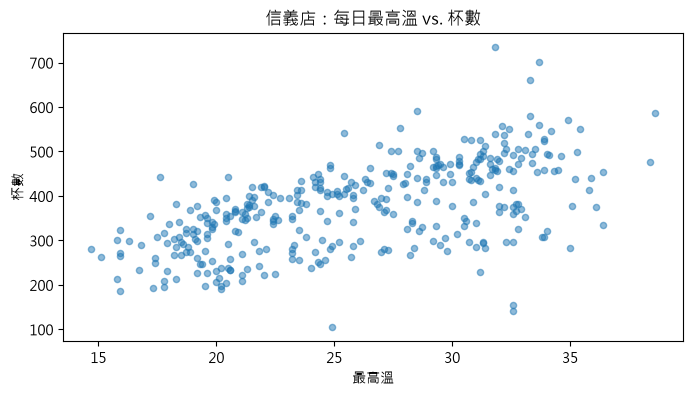

In [8]:
import matplotlib.pyplot as plt

ax = weather.plot.scatter(x='最高溫', y='杯數', alpha=0.5, figsize=(8, 4), title='信義店：每日最高溫 vs. 杯數')
plt.show()

> 💡 **看懂結果**：
> - 最高溫和杯數是**正相關**——天氣越熱越好賣；降雨量則是**負相關**。營運長可以參考氣象預報調整排班與備料。
> - 店員方面，加購率高的人，顧客評分也比較高、客訴比較少——**很會推薦的店員，通常也是服務好的店員**。
> - ⚠️ 但「相關」不等於「因果」：信義店冬天生意差，除了天冷，也可能是年底商辦區的作息變化。散佈圖中週末的點特別低，就是另一個影響因素（星期幾）。
>
> 🤖 **換你問 AI**：「請計算每日最高溫、降雨量與杯數的相關係數，畫散佈圖，並用白話解釋結果，提醒我相關不等於因果。」

---

## ✍️ 練習題

1. 找出每家門市「每日杯數」最高的店員（提示：先依門市、每日杯數排序，再用 `drop_duplicates('門市')`）。
2. 用 `weather` 計算「星期六、日」與「星期一～五」的平均杯數，信義店是平日好還是假日好？
3. 只看氣溫 30 度以上的日子，最高溫與杯數的相關係數還一樣高嗎？為什麼？

## 🔑 參考解答（先自己試試看！）

In [9]:
# 練習 1
best = staff.sort_values(['門市', '每日杯數'], ascending=[True, False]).drop_duplicates('門市')
print(best[['門市', '姓名', '每日杯數']])

# 練習 2
weekend = weather['星期'].isin(['星期六', '星期日'])
print('假日平均：', round(weather.loc[weekend, '杯數'].mean()), '平日平均：', round(weather.loc[~weekend, '杯數'].mean()))

# 練習 3
hot = weather[weather['最高溫'] >= 30]
print('30 度以上：', round(hot['最高溫'].corr(hot['杯數']), 3), '（範圍變窄，星期幾的影響相對變大，相關係數會下降）')

         門市   姓名   每日杯數
員工編號                   
E013  台中逢甲店  徐柏翰  127.9
E004  台北信義店  江心怡  119.6
E009  台北西門店  呂思妤  118.8
E017  台南成大店  黃俊傑  124.6
E024  高雄巨蛋店  張書豪   97.3
假日平均： 286 平日平均： 413
30 度以上： 0.138 （範圍變窄，星期幾的影響相對變大，相關係數會下降）
